In [ ]:
import matplotlib.pyplot as plt
import os
import numpy as np
from monai.transforms import LoadImage, EnsureChannelFirst, Orientation, Compose
from monai.bundle import ConfigParser, download
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import SGD
import seaborn as sns



In [3]:
import os

# Define the path to the main directory
testing_subset_path = '../data/Inputs/takotsubo_cases/testing_subset/'

min_slices = float('inf')

# Loop through all folders in the directory
for folder_name in sorted(os.listdir(testing_subset_path)):
    folder_path = os.path.join(testing_subset_path, folder_name)
    
    # Check if the path is a directory
    if os.path.isdir(folder_path):
        print(folder_name)
    
        dicom_files_folder = os.path.join(folder_path, "dicom", "EXP00000")
        print(dicom_files_folder)
        num_slices = len(os.listdir(dicom_files_folder))
        min_slices = min(min_slices, num_slices)
        print(num_slices)
        
        # for dicom_file in sorted(os.listdir(dicom_files_folder)):
        #     print(f"    {dicom_file}")
print(f"Min_slices: {min_slices}")  

JNMP 02291631
../data/Inputs/takotsubo_cases/testing_subset/JNMP 02291631/dicom/EXP00000
151
JNMP 2nd scan
../data/Inputs/takotsubo_cases/testing_subset/JNMP 2nd scan/dicom/EXP00000
96
JOS 3812401
../data/Inputs/takotsubo_cases/testing_subset/JOS 3812401/dicom/EXP00000
142
LET 04456356
../data/Inputs/takotsubo_cases/testing_subset/LET 04456356/dicom/EXP00000
982
LMA 03884426
../data/Inputs/takotsubo_cases/testing_subset/LMA 03884426/dicom/EXP00000
334
LMC 03629185
../data/Inputs/takotsubo_cases/testing_subset/LMC 03629185/dicom/EXP00000
210
LMD 22194237
../data/Inputs/takotsubo_cases/testing_subset/LMD 22194237/dicom/EXP00000
344
LW 12109724
../data/Inputs/takotsubo_cases/testing_subset/LW 12109724/dicom/EXP00000
235
MC 03887643
../data/Inputs/takotsubo_cases/testing_subset/MC 03887643/dicom/EXP00000
159
MDW 2286750
../data/Inputs/takotsubo_cases/testing_subset/MDW 2286750/dicom/EXP00000
111
MG 22519714
../data/Inputs/takotsubo_cases/testing_subset/MG 22519714/dicom/EXP00000
92
MGR 025

In [ ]:
# dicom_file_path = 'data/normal_cases/AG 519880_37F/DICOM/EXP00000/'
# dicom_file_path = 'data/normal_cases/ASJ 05633540_68F/DICOM/EXP00000/'
dicom_file_path = '../data/takotsubo_cases/testing_subset/JNMP 02291631/DICOM/EXP00000/'
# dicom_file_path = '../data/takotsubo_cases/testing_subset/JOS 3812401/DICOM/EXP00000/'

input_folder = "../data/Inputs/takotsubo_cases/testing_subset/JNMP 02291631/"
output_folder = "../data/Outputs/takotsubo_cases/testing_subset/JNMP 02291631"




image_loader = LoadImage(image_only=True)
CT = image_loader(dicom_file_path)

CT.meta

{'00200037': {'vr': 'DS', 'Value': [1.0, 0.0, 0.0, 0.0, 1.0, 0.0]},
 '00200032': {'vr': 'DS', 'Value': [-199.6093, -199.6093, 1796.5]},
 '00280030': {'vr': 'DS', 'Value': [0.781, 0.781, 2.0]},
 'spacing': array([0.781, 0.781, 2.   ]),
 'lastImagePositionPatient': array([-199.6093, -199.6093, 1496.5   ]),
 spatial_shape: (512, 512, 151),
 space: RAS,
 original_affine: array([[-7.810000e-01,  0.000000e+00,  0.000000e+00,  1.996093e+02],
        [ 0.000000e+00, -7.810000e-01,  0.000000e+00,  1.996093e+02],
        [ 0.000000e+00,  0.000000e+00, -2.000000e+00,  1.796500e+03],
        [ 0.000000e+00,  0.000000e+00,  0.000000e+00,  1.000000e+00]]),
 affine: tensor([[-7.8100e-01,  0.0000e+00,  0.0000e+00,  1.9961e+02],
         [ 0.0000e+00, -7.8100e-01,  0.0000e+00,  1.9961e+02],
         [ 0.0000e+00,  0.0000e+00, -2.0000e+00,  1.7965e+03],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00,  1.0000e+00]],
        dtype=torch.float64),
 original_channel_dim: nan,
 'filename_or_obj': '../data/t

In [ ]:
import nibabel as nib
from totalsegmentator.python_api import totalsegmentator


# option 1: provide input and output as file paths
# output_directory = "../data/segment_eval_output_takotsubo_case2_bodyseg"
output_image = totalsegmentator(dicom_file_path, output_folder, license_number="aca_BWYHC6UQQFDU8A", task="heartchambers_highres", body_seg=True)

# option 2: provide input and output as nifti image objects
# input_img = nib.load(dicom_file_path)
# output_img = totalsegmentator(input_img)
# print(output_img)
# nib.save(output_img, data_directory)

No GPU detected. Running on CPU. This can be very slow. The '--fast' or the `--roi_subset` option can help to reduce runtime.

If you use this tool please cite: https://pubs.rsna.org/doi/10.1148/ryai.230024

Generating rough segmentation for cropping...
Converting dicom to nifti...
  found image with shape (512, 512, 151)
Resampling...
  Resampled in 1.17s
Predicting...


/Users/awabakram/git/Takotsubo-Syndrome/myenv/lib/python3.9/site-packages/nnunetv2/inference/predict_from_raw_data.py:84: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  check

  Predicted in 11.73s
Resampling...
Converting dicom to nifti...
  found image with shape (512, 512, 151)
  cropping from (512, 512, 151) to (197, 182, 46)
Predicting...


/Users/awabakram/git/Takotsubo-Syndrome/myenv/lib/python3.9/site-packages/nnunetv2/inference/predict_from_raw_data.py:84: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  check

  Predicted in 480.15s
Saving segmentations...


  0%|          | 0/7 [00:00<?, ?it/s]

Creating heart_myocardium.nii.gz
Creating heart_atrium_left.nii.gz
Creating heart_ventricle_left.nii.gz
Creating heart_atrium_right.nii.gz
Creating heart_ventricle_right.nii.gz
Creating aorta.nii.gz
Creating pulmonary_artery.nii.gz
  Saved in 1.60s



<class 'nibabel.nifti1.Nifti1Image'>
data shape (512, 512, 151)
affine:
[[-7.81000018e-01  0.00000000e+00  0.00000000e+00  1.99609299e+02]
 [-0.00000000e+00  7.81000018e-01  0.00000000e+00 -1.99481705e+02]
 [ 0.00000000e+00 -0.00000000e+00  2.00000000e+00  1.49650000e+03]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
metadata:
<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b''
dim_info        : 0
dim             : [  3 512 512 151   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : uint8
bitpix          : 8
slice_start     : 0
pixdim          : [-1.     0.781  0.781  2.     1.     1.     1.     1.   ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 2
cal_max         : 0.0
cal_min 

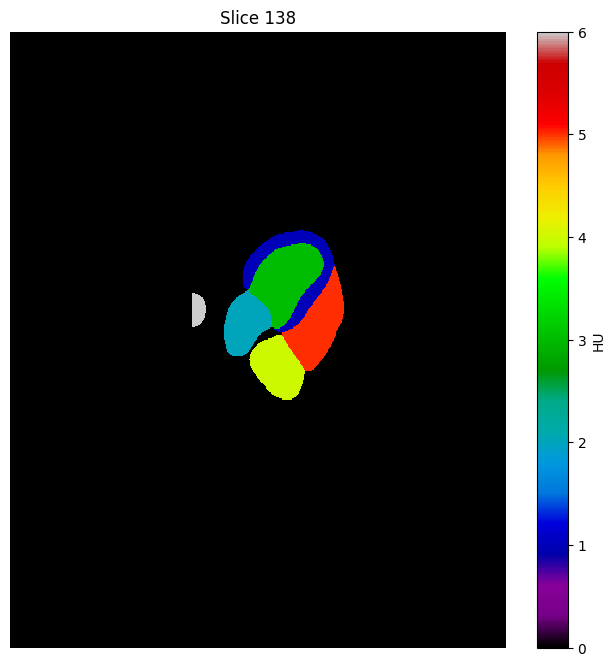

In [ ]:
nib.save(output_image, f'{output_folder}/output_image.nii.gz')
%matplotlib inline
slice_num = 138

print(output_image)

plt.figure(figsize=(8,8))
plt.pcolormesh(output_image.get_fdata()[:, : , slice_num], cmap='nipy_spectral')
plt.colorbar(label='HU')
plt.title(f"Slice {slice_num}")
plt.axis('off')
plt.show()

<class 'monai.data.meta_tensor.MetaTensor'>
torch.Size([512, 512, 151])


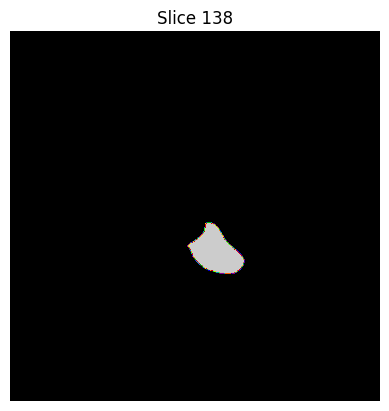

In [ ]:
# Load the image
image = image_loader(f"{output_folder}/heart_ventricle_left.nii.gz")


# Check the image type and shape
print(type(image))  # Should be a PyTorch Tensor or NumPy array
print(image.shape)  # Shows the dimensions of the loaded image

slice_num = 138

# Display a slice of the image
plt.imshow(image[:, :, slice_num], cmap='nipy_spectral')
plt.title(f"Slice {slice_num}")
plt.axis('off')
plt.show()